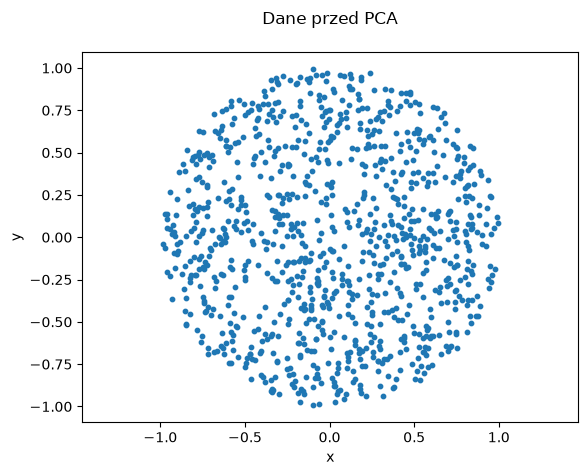

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000
kąt = np.random.uniform(0, 2 * np.pi, n)
promień = np.sqrt(np.random.uniform(0, 1, n))
x = promień * np.cos(kąt)
y = promień * np.sin(kąt)
plt.scatter(x, y, s=10)
plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dane przed PCA\n")
plt.show()

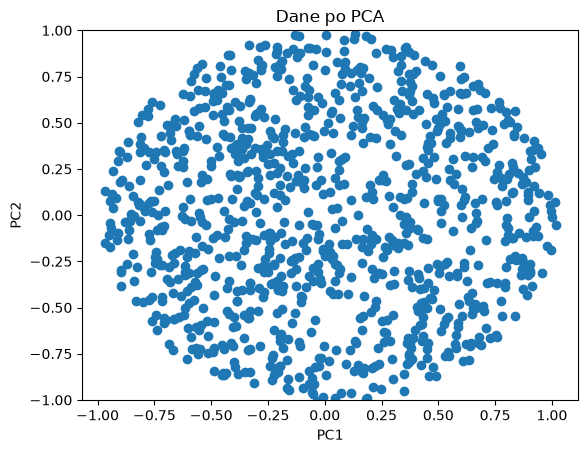

[0.50658635 0.49341365]
[[-0.65273581  0.75758561]
 [ 0.75758561  0.65273581]]


In [2]:
from sklearn.decomposition import PCA

X = np.column_stack([x, y])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.ylim(-1, 1)
plt.title("Dane po PCA")
plt.show()
print(pca.explained_variance_ratio_)
print(pca.components_)

In [26]:
import numpy as np

X = np.array([[1, 2, 5], [2, 1, 10], [3, 4, -1], [4, 3, 3], [5, 7, 6]], dtype=float)
print(X.shape)

(5, 3)


In [29]:
X_c = X - X.mean(axis=0)
print(X_c.shape)

(5, 3)


In [ ]:
print(X_c.mean(axis=0))  # wynik:[0.0, 8.88178e-17, 3.552714e-16]

[0.00000000e+00 8.88178420e-17 3.55271368e-16]


In [33]:
macierz_kowariancji = (X_c.T @ X_c) / (X_c.shape[0] - 1)
macierz_kowariancji


array([[ 2.5 ,  3.  , -1.25],
       [ 3.  ,  5.3 , -2.8 ],
       [-1.25, -2.8 , 16.3 ]])

In [ ]:
wartosci_wlasne, wektory_wlasne = np.linalg.eigh(macierz_kowariancji)

idx = np.argsort(wartosci_wlasne)[::-1]
wartosci_wlasne = wartosci_wlasne[idx]
wektory_wlasne = wektory_wlasne[:, idx]

for i in range(2):
    eigenvalue = wartosci_wlasne[i]
    eigenvector = wektory_wlasne[:, i]
    lhs = macierz_kowariancji @ eigenvector
    rhs = eigenvalue * eigenvector
    print(f"\n\n ---Wektor własny numer {i + 1}---")
    print(f"C @ w:\n{lhs}")
    print(f"lambda * w:\n{rhs}")



 ---Wektor własny numer 1---
C @ w:
[-2.30499925 -4.44874894 16.48578142]
lambda * w:
[-2.30499925 -4.44874894 16.48578142]


 ---Wektor własny numer 2---
C @ w:
[3.35686835 5.00388824 1.81966634]
lambda * w:
[3.35686835 5.00388824 1.81966634]


In [39]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)
indeksy = np.argsort(wartosci_wlasne)[::-1]
print(indeksy)
posortowane_wart_własne = wartosci_wlasne[indeksy]
print(f"PCA moje (wariancja):\n{posortowane_wart_własne}")
print(f"PCA sklearn (wariancja):\n{pca.explained_variance_}")

posortowane_wekt_własne = wektory_wlasne[:, indeksy]
print("\n")
print(f"PCA moje (kierunki):\n{posortowane_wekt_własne}")
print(f"PCA sklearn (kierunki):\n{pca.components_.T}")

[0 1 2]
PCA moje (wariancja):
[17.23036209  6.29433462  0.57530329]
PCA sklearn (wariancja):
[17.23036209  6.29433462  0.57530329]


PCA moje (kierunki):
[[-0.13377544  0.53331584  0.83527142]
 [-0.25819242  0.79498288 -0.54894344]
 [ 0.95678671  0.2890959  -0.03134893]]
PCA sklearn (kierunki):
[[-0.13377544  0.53331584  0.83527142]
 [-0.25819242  0.79498288 -0.54894344]
 [ 0.95678671  0.2890959  -0.03134893]]


In [42]:
udzial_moj = posortowane_wart_własne / posortowane_wart_własne.sum()

print(f"Udział wariancji (moje):\n{udzial_moj}")
print(f"Udział wariancji (sklearn):\n{pca.explained_variance_ratio_}")

Udział wariancji (moje):
[0.71495278 0.26117571 0.02387151]
Udział wariancji (sklearn):
[0.71495278 0.26117571 0.02387151]


In [43]:
ile_składowych = 2
wybrane_wartości = wartosci_wlasne[:ile_składowych]
wybrane_wektory = wektory_wlasne[:, :ile_składowych]
print("Wybrane wartości własne:")
print(wybrane_wartości)
print("\nWybrane wektory własne:")
print(wybrane_wektory)
X_transformed = X_c @ wybrane_wektory  # Rzutowanie
print("\nDane w nowej przestrzeni:")
print(X_transformed)
print(X_transformed.shape)

Wybrane wartości własne:
[17.23036209  6.29433462]

Wybrane wektory własne:
[[-0.13377544  0.53331584]
 [-0.25819242  0.79498288]
 [ 0.95678671  0.2890959 ]]

Dane w nowej przestrzeni:
[[ 1.01173495 -2.06396935]
 [ 5.92008548 -0.88015688]
 [-5.51292102 -1.14194732]
 [-1.5613572  -0.24723075]
 [ 0.14245779  4.3333043 ]]
(5, 2)


# Zadanie 1

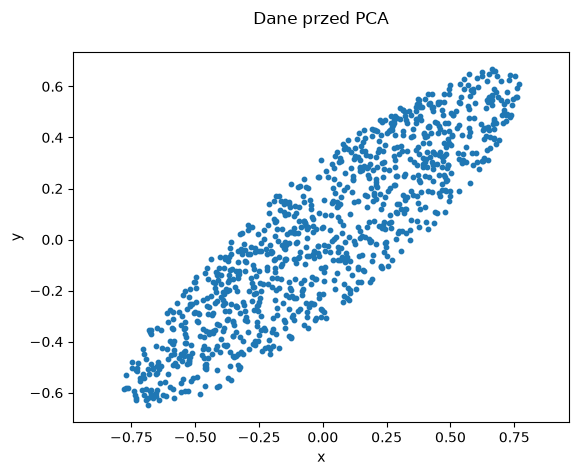

In [9]:
n = 1000
kąt = np.random.uniform(0, 2 * np.pi, n)
promień = np.sqrt(np.random.uniform(0, 1, n))
x = promień * np.cos(kąt)
y = (promień * 0.25) * np.sin(kąt)
kat_rot = np.deg2rad(40)
x_rot = x * np.cos(kat_rot) - y * np.sin(kat_rot)
y_rot = x * np.sin(kat_rot) + y * np.cos(kat_rot)
plt.scatter(x_rot, y_rot, s=10)
plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dane przed PCA\n")
plt.show()

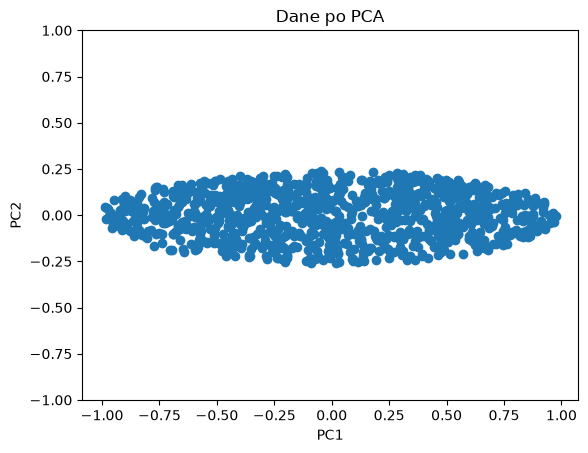

[0.94668368 0.05331632]
[[ 0.76580529  0.64307252]
 [-0.64307252  0.76580529]]


In [10]:
from sklearn.decomposition import PCA

X = np.column_stack([x_rot, y_rot])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.ylim(-1, 1)
plt.title("Dane po PCA")
plt.show()
print(pca.explained_variance_ratio_)
print(pca.components_)

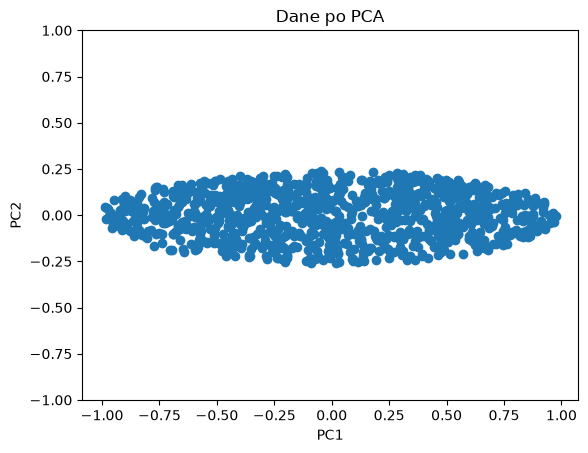

[0.94668368 0.05331632]
[[ 9.99999931e-01  3.71978931e-04]
 [-3.71978931e-04  9.99999931e-01]]


In [11]:
from sklearn.decomposition import PCA

X = np.column_stack([x, y])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.ylim(-1, 1)
plt.title("Dane po PCA")
plt.show()
print(pca.explained_variance_ratio_)
print(pca.components_)

# Zadanie 2

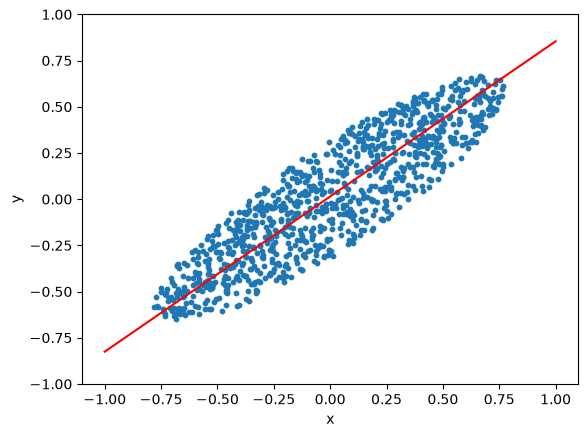

[0.94668368 0.05331632]
[[ 0.76580529  0.64307252]
 [-0.64307252  0.76580529]]


In [18]:
from sklearn.decomposition import PCA

X = np.column_stack([x_rot, y_rot])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

v_x, v_y = pca.components_[0]
x_sr, y_sr = X.mean(axis=0)

xs = np.linspace(-1, 1, 100)
ys = (v_y / v_x) * (xs - x_sr) + y_sr


plt.scatter(x_rot, y_rot, s=10)
plt.plot(xs, ys, "r", label="PC1")
plt.xlabel("x")
plt.ylabel("y")
plt.ylim(-1, 1)
plt.show()
print(pca.explained_variance_ratio_)
print(pca.components_)